In [8]:
!pip install nltk
!pip install wordcloud

  Using cached wordcloud-1.9.4-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (3.4 kB)
Using cached wordcloud-1.9.4-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (537 kB)


In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from collections import Counter
from wordcloud import WordCloud


[nltk_data] Downloading package wordnet to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/students/s346259/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<h2>File reading</h2>

In [10]:
data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data

#remove every character that is not a letter or a number
data['body'] = data['body'].str.replace(r'[^a-zA-Z\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase

data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

#lemmatize data
lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

In [11]:
word_counts = data['body'].str.split().explode().value_counts()
#remove_words = set(word_counts[word_counts < 100].index)#removing words that appear less than 100 times in the dataset
remove_words = set(word_counts.nlargest(100).index)#removing the 100 most frequent words (stopwords)

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

most_frequent_words = set(word_counts.nlargest(140000).index)

def keep_most_frequent_words(text):
    return ' '.join([word for word in text.split() if word in most_frequent_words])

data['body'] = data['body'].apply(keep_most_frequent_words)

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments

In [12]:
data['word_count'] = data['body'].str.split().apply(len)
data = data[data['word_count'] >= 10] #keep comments with at least 10 words
data = data[data['word_count'] <= 500] #keep comments with at most 500 words

In [13]:
vectorizer = CountVectorizer()
#vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_106/2114926568.py:14: SyntaxWarning: invalid escape sequence '\s'
  plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')


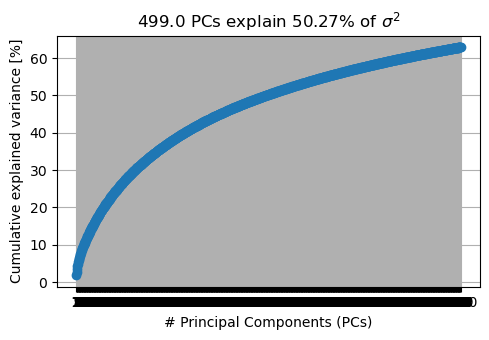

62.943960697174376


In [14]:
PCA_number_components=1000
pca=PCA(n_components=PCA_number_components,random_state=42,)
pca.fit(vectorizedData)
explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
plt.xticks([i for i in range(PCA_number_components)], [i for i in range(1,PCA_number_components+1)])
plt.grid()
plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')
plt.tight_layout()
plt.show()

print(perc_cumul_exp_var[-1])
vectorizedData = pca.transform(vectorizedData)
pd.DataFrame(vectorizedData).to_csv("unsupervised_BoW_PCA.csv")

In [15]:
vectorizedData=pd.read_csv("unsupervised_BoW_PCA.csv", index_col=0).to_numpy()

<h2>Determining the number of clusters</h2>

In [16]:
def plot_clustering_error_and_silhouette(clustering_data,silhouetteScores):
    fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

    axs[0].plot(
        [k for k in k_values], 
        [result.inertia_ for result in clustering_data]
    )
    axs[0].set_xlabel("Number of clusters k")
    axs[0].set_ylabel("Clustering error")
    axs[0].grid()
    
    axs[1].plot(
        [k for k in k_values], 
        [s for s in silhouetteScores]
    )
    axs[1].set_xlabel("Number of clusters k")
    axs[1].set_ylabel("Silhouette")#Compute the mean Silhouette Coefficient of all samples.
    axs[1].grid()

    plt.tight_layout()
    plt.show()

Trying to use "k-means++" as init instead of random initialization
centroids are equally spaced -> probably better results than random initialization
also it should converge faster

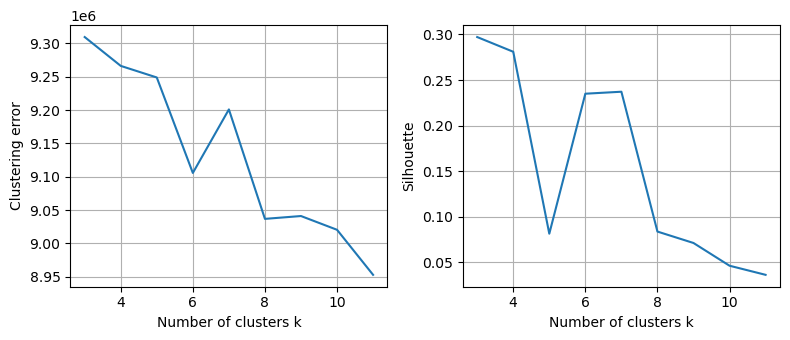

In [17]:
n_clusters=2
kmeans = KMeans(
    n_clusters, #will be choosen later
    init='random', #centroids are initialized randomly
    #init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
    random_state=None, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300
    )
kmeans_results = []
k_values=pd.Series(range(3, 12, 1))#this will need to be changed
for k in k_values:
    kmeans_results.append(KMeans(n_clusters=k).fit(vectorizedData))
    #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

n_sample=100000
silhouetteScores = []
for result in kmeans_results:
    #print(len(np.unique(result.labels_)))
    try:
        silhouetteScores.append(silhouette_score(vectorizedData, result.labels_, sample_size=n_sample))
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)
    
plot_clustering_error_and_silhouette(kmeans_results,silhouetteScores)

In [18]:
numberOfChoosenClusters=4
indexOfChoosenCluster = k_values[k_values == numberOfChoosenClusters].index[0]

<h2>User Distribution Analysis</h2>

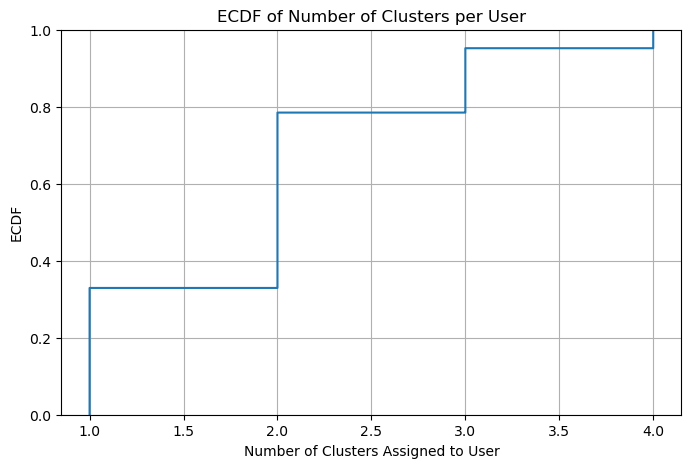

In [19]:
#data.insert(loc=1,column="cluster",value=kmeans_results[indexOfChoosenCluster].labels_)#adding labels to each comment
data["cluster"]= kmeans_results[indexOfChoosenCluster].labels_
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

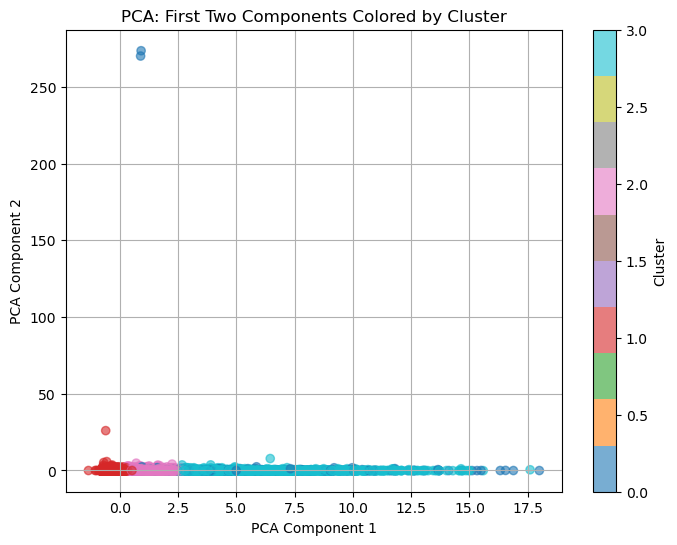

In [20]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(vectorizedData[:, 0], vectorizedData[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA: First Two Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

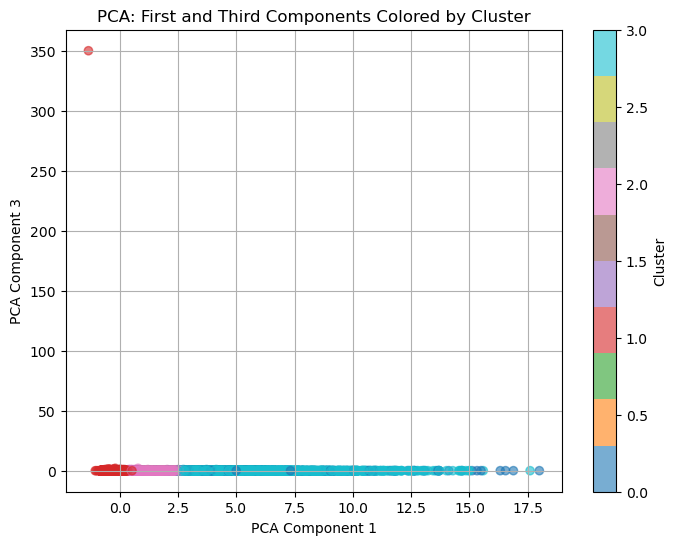

In [21]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(vectorizedData[:, 0], vectorizedData[:, 2], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 3')
plt.title('PCA: First and Third Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

<h3>Cluster analysis</h3>

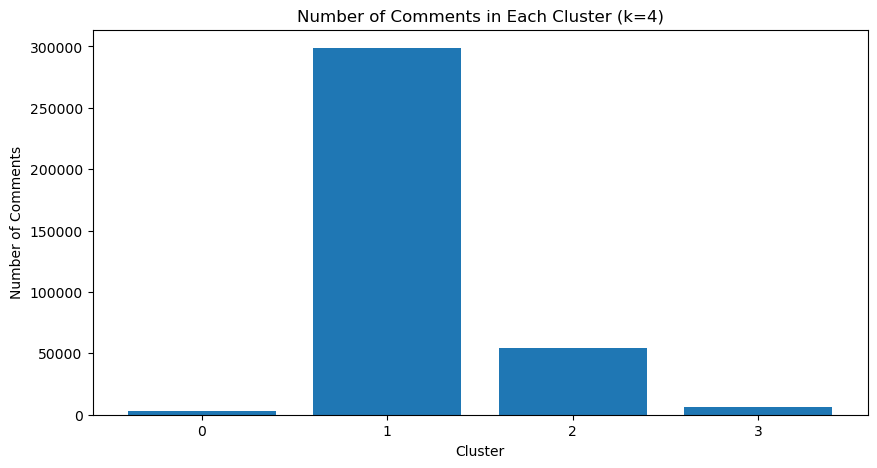

Cluster sizes: cluster
1    298686
2     54283
3      6244
0      3087
Name: count, dtype: int64


In [22]:
#Plot the number of comments for each cluster
cluster_sizes = data['cluster'].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(cluster_sizes.index, cluster_sizes.values)
plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
plt.xlabel("Cluster")
plt.ylabel("Number of Comments")
plt.xticks(cluster_sizes.index)
plt.show()
print("Cluster sizes:", cluster_sizes)

In [23]:
!pip install WordCloud

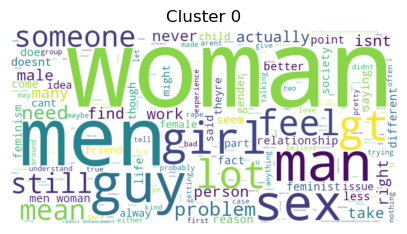

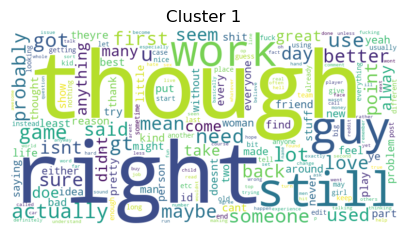

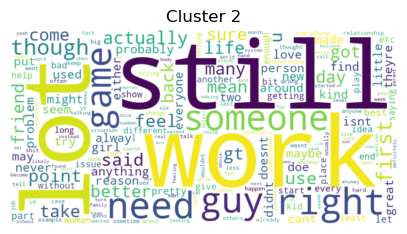

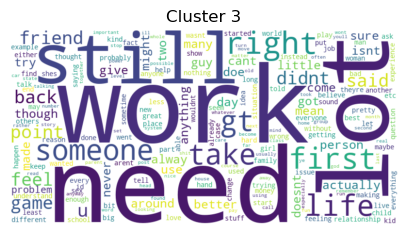

In [24]:
texts_dict = {}
# Prepare texts for each cluster
for i in range(0, numberOfChoosenClusters):
    texts_dict[i] = " ".join(data[data['cluster'] == i]['body'].values)

# Generate and display word clouds for each cluster
for i in range(0, numberOfChoosenClusters):
    if cluster_sizes[i] > 5 and texts_dict[i]:
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(texts_dict[i])

        plt.figure(figsize=(5, 3))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')  
        plt.title(f"Cluster {i}")
        plt.show()
    else:
        print(f"Cluster {i} is too small to display, printing each comment instead:")
        for _, comment in data[data['cluster'] == i].iterrows():
            print(f"author: {comment['author']}, subreddit: {comment['subreddit']}, body: {comment['body']}")

<h2>Subreddit distribution</h2>

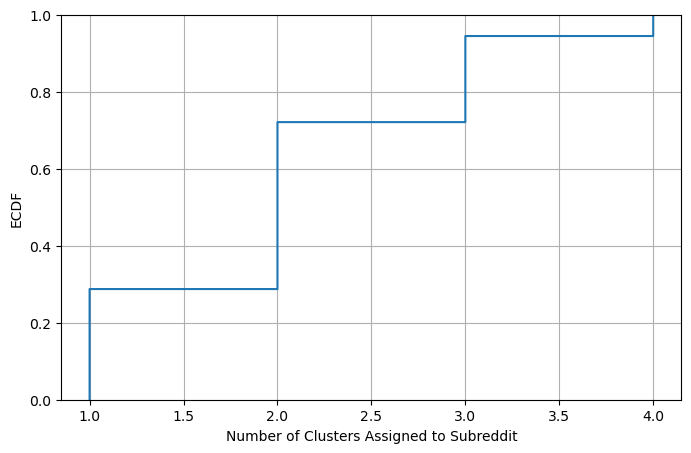

In [25]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0 has 3087 comments


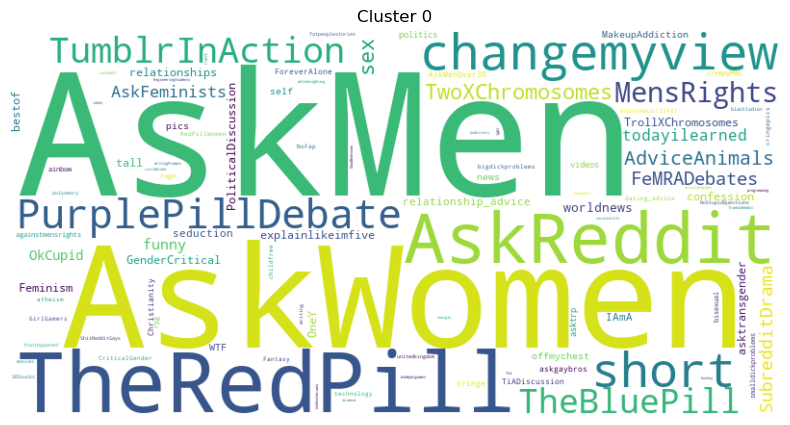

Cluster 1 has 298686 comments


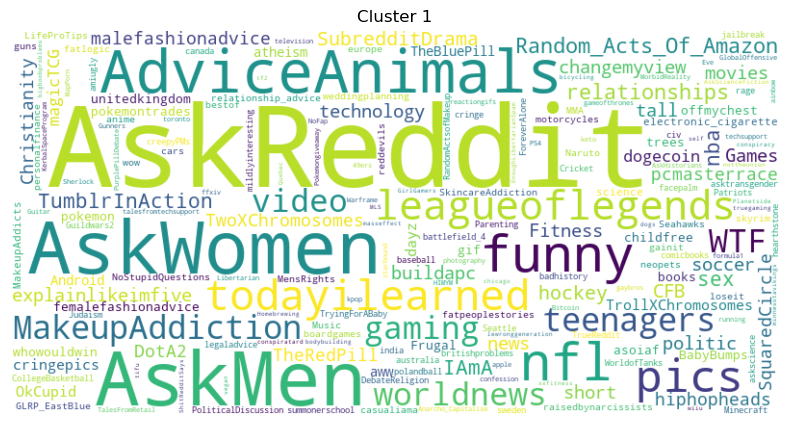

Cluster 2 has 54283 comments


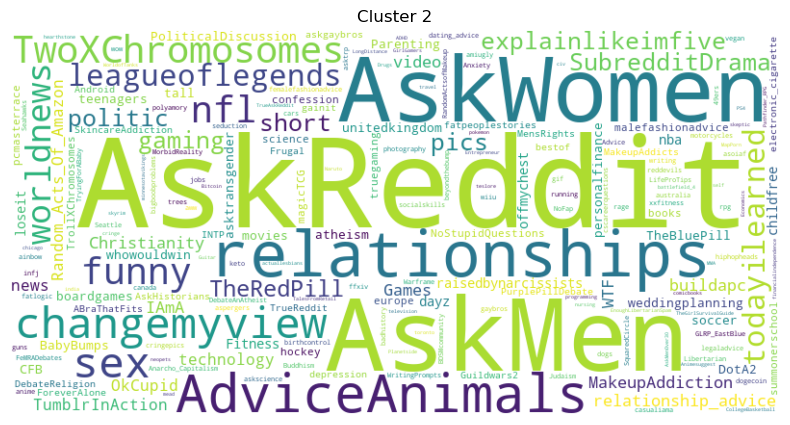

Cluster 3 has 6244 comments


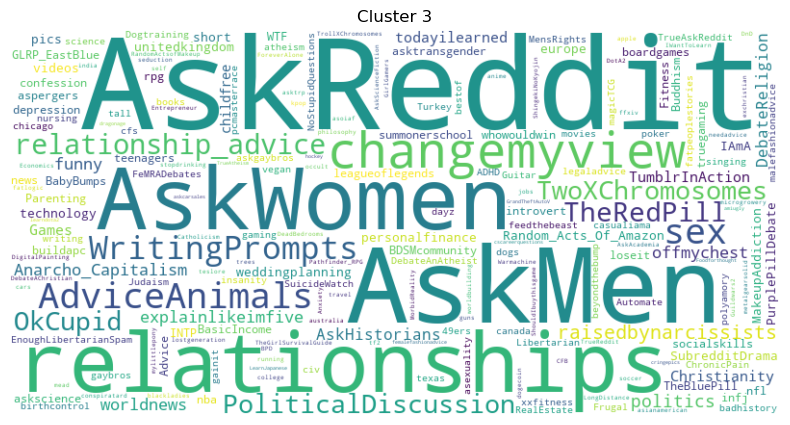

In [26]:
subredditsNames = []
for i in range(0, numberOfChoosenClusters):
    print(f"Cluster {i} has {cluster_sizes[i]} comments")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()